In [2]:
import os
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torchvision import datasets

DATA_DIR = Path("D:\\Загрузки\\Mushrooms") 
classes = sorted([d.name for d in DATA_DIR.iterdir() if d.is_dir()])
print(f"Найдено классов: {len(classes)}")
print("Список классов:", classes)

Найдено классов: 9
Список классов: ['Agaricus', 'Amanita', 'Boletus', 'Cortinarius', 'Entoloma', 'Hygrocybe', 'Lactarius', 'Russula', 'Suillus']


Проверяем целостностность файлов
---

In [3]:
records = []
corrupted_files = []

for cls in classes:
    cls_dir = DATA_DIR / cls
    for img_path in cls_dir.iterdir():
        if not img_path.is_file():
            continue
        try:
            with Image.open(img_path) as img:
                img.verify()
            
            with Image.open(img_path) as img:
                w, h = img.size
                mode = img.mode
                records.append({
                    "class": cls,
                    "path": str(img_path),
                    "width": w,
                    "height": h,
                    "mode": mode
                })
        except Exception as e:
            corrupted_files.append((str(img_path), str(e)))

df = pd.DataFrame(records)

print(f"Неиспорченных изображений: {len(df)}")
print(f"Неисправных файлов: {len(corrupted_files)}")
if corrupted_files:
    print("Примеры corrupted_files:", corrupted_files[:5])

print("\nРаспределение цветовых режимов:")
print(df["mode"].value_counts())

print("\nРазрешение (ширина х высота):")
print(df[["width", "height"]].describe().round(1))

Неиспорченных изображений: 6714
Неисправных файлов: 0

Распределение цветовых режимов:
mode
RGB    6712
L         2
Name: count, dtype: int64

Разрешение (ширина х высота):
        width  height
count  6714.0  6714.0
mean    796.2   579.8
std     132.8   100.1
min     259.0   152.0
25%     800.0   533.0
50%     800.0   580.0
75%     800.0   600.0
max    1280.0  1024.0


Визуализация баланса классов
---

C:\Users\inkin\AppData\Local\Temp\ipykernel_26876\2730942530.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette="viridis")


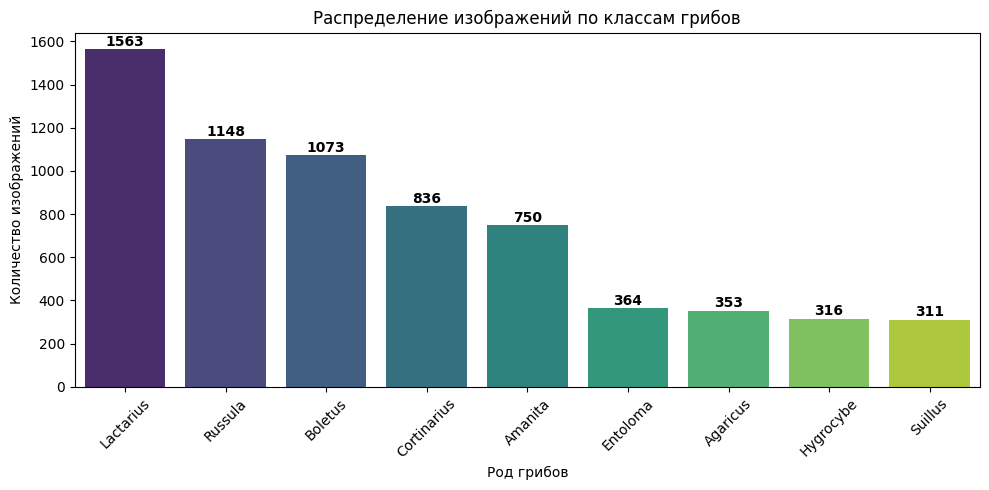

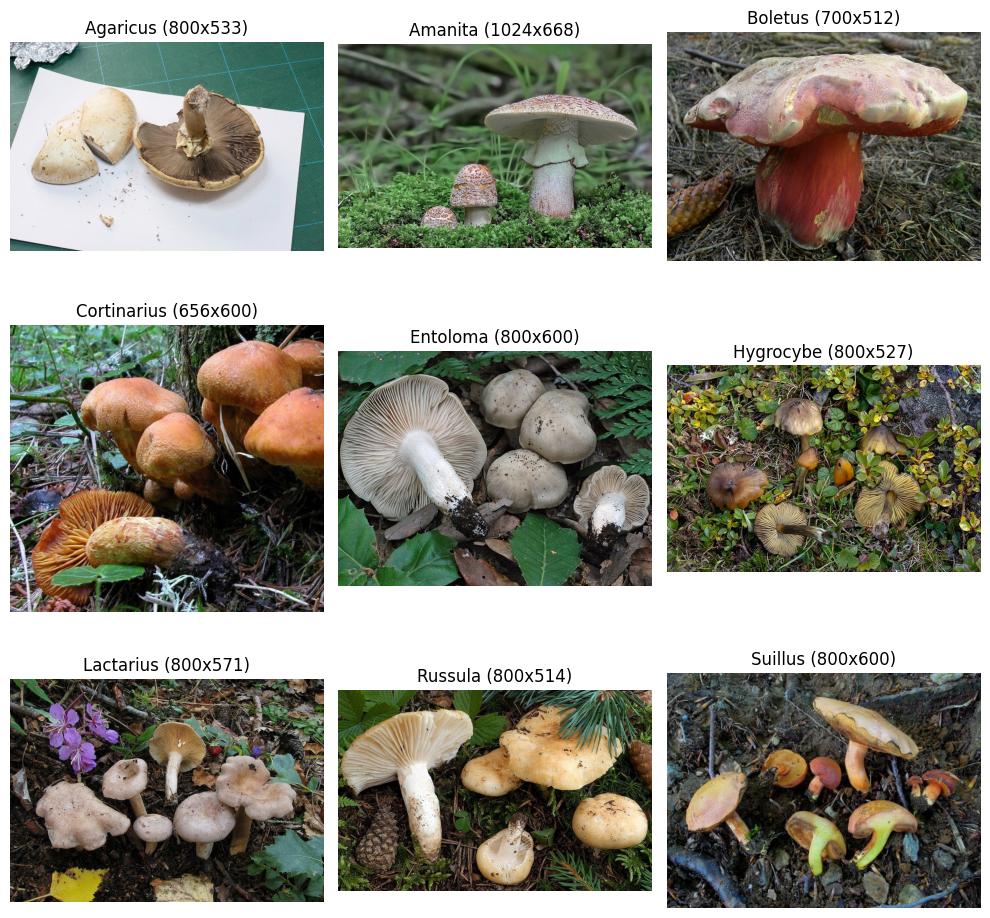

In [4]:
plt.figure(figsize=(10, 5))
class_counts = df["class"].value_counts()
sns.barplot(x=class_counts.index, y=class_counts.values, palette="viridis")
plt.title("Распределение изображений по классам грибов")
plt.xlabel("Род грибов")
plt.ylabel("Количество изображений")
plt.xticks(rotation=45)

for i, v in enumerate(class_counts.values):
    plt.text(i, v + 15, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for ax, cls in zip(axes.flat, classes):
    sample_path = df[df["class"] == cls]["path"].sample(1, random_state=42).values[0]
    img = Image.open(sample_path).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{cls} ({img.size[0]}x{img.size[1]})")
    ax.axis("off")

plt.tight_layout()
plt.show()

Заметен значительный дисбаланс (разница: примерно в 5 раз), также видно, что грибы сняты в естественной среде с разным ракурсом и уровнем освещения. При обучении Accuracy будет перекошена в сторону более крупных классов, поэтому добавим macro F1-score. Обучать будем с помощью Transfer Learning.

Разбиваем датасет на train и test (80/20)
---

In [ ]:
import shutil
from sklearn.model_selection import train_test_split

SplitDir = Path("D:\\Загрузки\\Mushrooms_split")
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["class"])

for split_name, split_data in [("train", train_df), ("test", test_df)]:
    for _, row in split_data.iterrows():
        cls_name = row["class"]
        src_path = Path(row["path"])
        dst_dir = SplitDir / split_name / cls_name
        dst_dir.mkdir(parents=True, exist_ok=True)
        
        dst_path = dst_dir / src_path.name
        if not dst_path.exists():
            shutil.copy2(src_path, dst_path)

print(f"Train: {len(train_df)}, Test: {len(test_df)}")

Train: 5371, Test: 1343


Удаление обрезанных файлов
---

In [13]:
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = False
SplitDir = Path("D:\\Загрузки\\Mushrooms_split")

bad_files = []
for split in ["train", "test"]:
    for root, _, files in os.walk(SplitDir / split):
        for file in files:
            path = os.path.join(root, file)
            try:
                with Image.open(path) as img:
                    img.load()
            except Exception as e:
                bad_files.append(path)
                os.remove(path)

print(f"Удалено файлов: {len(bad_files)}")

Удалено файлов: 2


Настройка Transfer
---

In [14]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Используемое устройство:", device)

weights = models.ResNet50_Weights.DEFAULT # Берем веса ResNet50
test_transforms = weights.transforms()

train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=25),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(root=SplitDir / "train", transform=train_transforms)
test_dataset = datasets.ImageFolder(root=SplitDir / "test", transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)

print("Классы:", train_dataset.classes)

Используемое устройство: cpu
Классы: ['Agaricus', 'Amanita', 'Boletus', 'Cortinarius', 'Entoloma', 'Hygrocybe', 'Lactarius', 'Russula', 'Suillus']


Сборка модели
---

In [15]:
targets = train_dataset.targets
class_counts = np.bincount(targets)
class_weights = 1.0 / torch.tensor(class_counts, dtype=torch.float)
class_weights = (class_weights / class_weights.sum() * len(classes)).to(device)
print("Веса классов:", np.round(class_weights.cpu().numpy(), 2))

model = models.resnet50(weights=weights)

for param in model.parameters():
    param.requires_grad = False # Заморозка слоев

num_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(num_features, len(classes))
)

model = model.to(device)

Веса классов: [1.52 0.71 0.5  0.64 1.45 1.7  0.34 0.46 1.68]


In [16]:
def train_model(model, train_loader, test_loader, criterion, optimizer, num_epochs=5):
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

    for epoch in range(num_epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        for inputs, labels in pbar:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, preds = outputs.max(1)
            total += labels.size(0)
            correct += preds.eq(labels).sum().item()
            pbar.set_postfix({"loss": f"{loss.item():.4f}", "acc": f"{correct/total:.4f}"})

        train_loss = running_loss / total
        train_acc = correct / total

        model.eval()
        test_loss, test_correct, test_total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                test_loss += loss.item() * inputs.size(0)
                _, preds = outputs.max(1)
                test_total += labels.size(0)
                test_correct += preds.eq(labels).sum().item()

        val_loss = test_loss / test_total
        val_acc = test_correct / test_total

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(val_loss)
        history["test_acc"].append(val_acc)

        print(f"Итог эпохи {epoch+1}: Train Acc = {train_acc:.4f} | Test Acc = {val_acc:.4f}\n")

    return history

Обучение головы классификатора
---

In [17]:
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.fc.parameters(), lr=1e-3)

history_stage1 = train_model(model, train_loader, test_loader, criterion, optimizer, num_epochs=10)

Epoch 1/10 [Train]: 100%|██████████| 202/202 [08:04<00:00,  2.40s/it, loss=0.9474, acc=0.4706]


Итог эпохи 1: Train Acc = 0.4706 | Test Acc = 0.6460



Epoch 2/10 [Train]: 100%|██████████| 202/202 [08:07<00:00,  2.41s/it, loss=1.4988, acc=0.6069]


Итог эпохи 2: Train Acc = 0.6069 | Test Acc = 0.6629



Epoch 3/10 [Train]: 100%|██████████| 202/202 [08:03<00:00,  2.39s/it, loss=0.8378, acc=0.6356]


Итог эпохи 3: Train Acc = 0.6356 | Test Acc = 0.7348



... (10 outputs left out)

Epoch 9/10 [Train]: 100%|██████████| 202/202 [08:08<00:00,  2.42s/it, loss=0.6283, acc=0.7086]


Итог эпохи 9: Train Acc = 0.7086 | Test Acc = 0.7902



Epoch 10/10 [Train]: 100%|██████████| 202/202 [08:11<00:00,  2.43s/it, loss=0.7358, acc=0.7043]


Итог эпохи 10: Train Acc = 0.7043 | Test Acc = 0.7753



In [18]:
# Сохранение
checkpoint = {
    "model_state_dict": model.state_dict(),
    "class_names": train_dataset.classes,
    "history": history_stage1
}

torch.save(checkpoint, "resnet50_mushrooms_stage1.pth")
print("Сохранено")

Сохранено


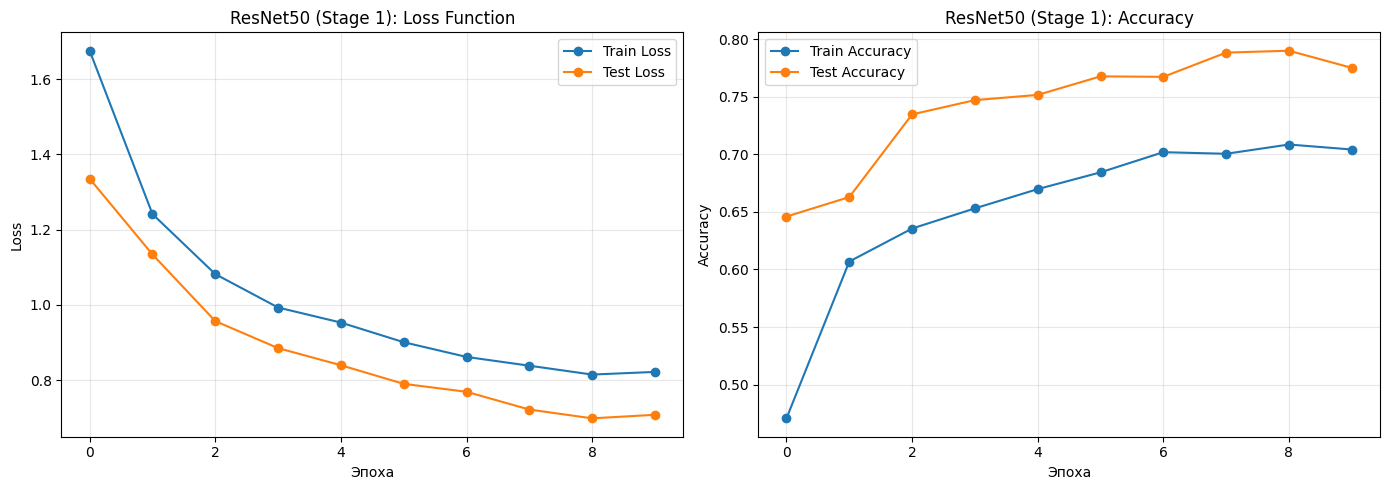

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history_stage1["train_loss"], label="Train Loss", marker="o")
ax1.plot(history_stage1["test_loss"], label="Test Loss", marker="o")
ax1.set_title("ResNet50 (Stage 1): Loss Function")
ax1.set_xlabel("Эпоха")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history_stage1["train_acc"], label="Train Accuracy", marker="o")
ax2.plot(history_stage1["test_acc"], label="Test Accuracy", marker="o")
ax2.set_title("ResNet50 (Stage 1): Accuracy")
ax2.set_xlabel("Эпоха")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Classification report на тестовой выборке:

              precision    recall  f1-score   support

    Agaricus     0.6258    0.7886    0.6978       123
     Amanita     0.7835    0.8413    0.8114       271
     Boletus     0.9008    0.9291    0.9147       381
 Cortinarius     0.7192    0.6192    0.6655       302
    Entoloma     0.7698    0.7239    0.7462       134
   Hygrocybe     0.7426    0.9182    0.8211       110
   Lactarius     0.7690    0.7852    0.7770       568
     Russula     0.8738    0.6337    0.7346       415
     Suillus     0.5810    0.8889    0.7027       117

    accuracy                         0.7753      2421
   macro avg     0.7517    0.7920    0.7635      2421
weighted avg     0.7856    0.7753    0.7740      2421



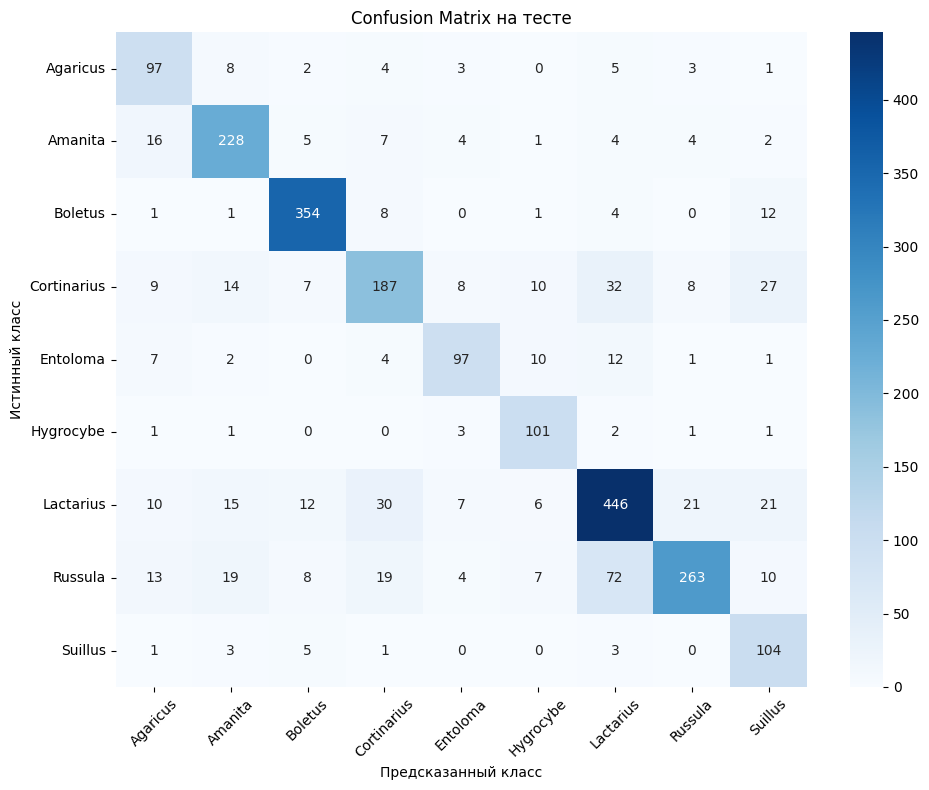

In [21]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

class_names = train_dataset.classes

print("Classification report на тестовой выборке:\n")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix на тесте")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Неверные предсказания
---

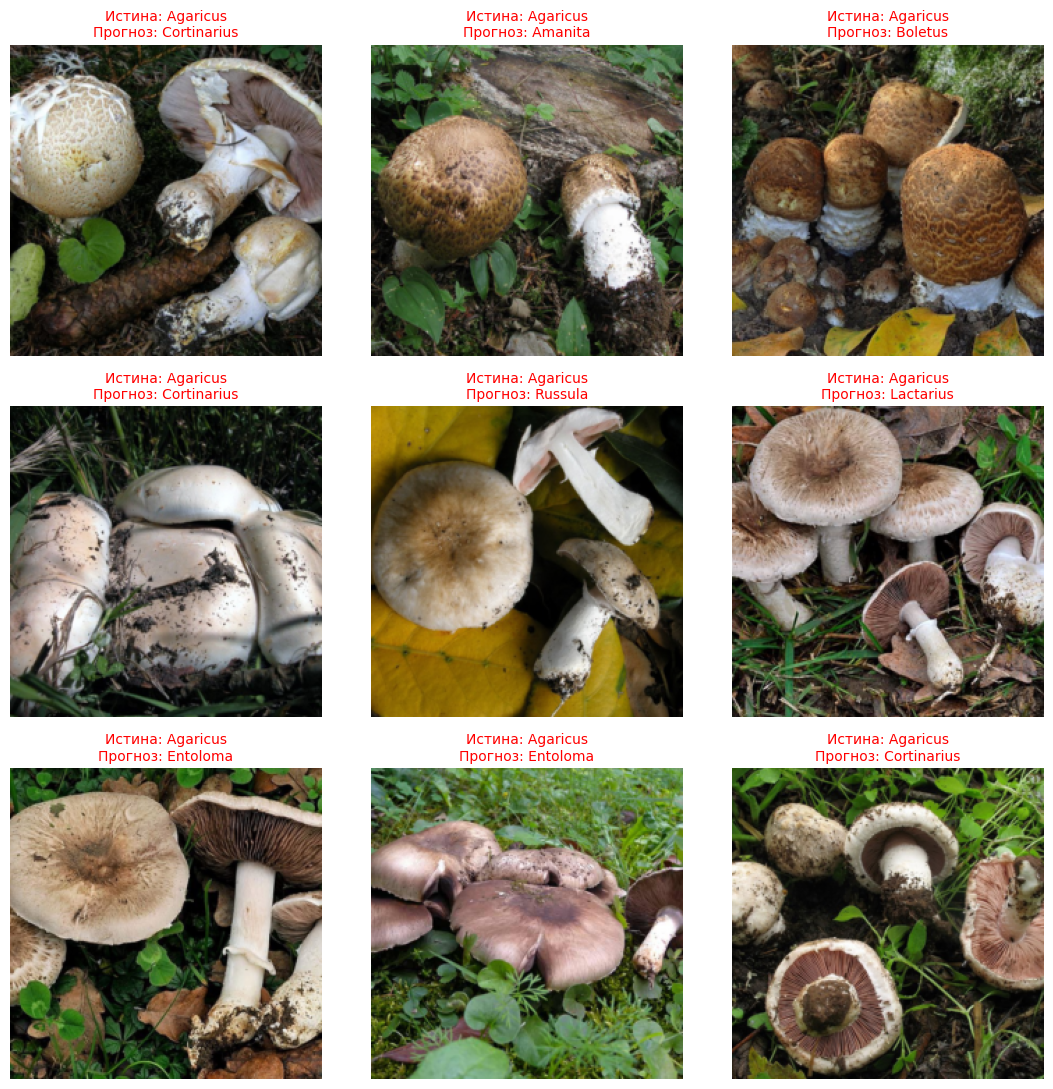

In [23]:
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

misclassified = []
model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs.to(device))
        _, preds = outputs.max(1)
        preds = preds.cpu()
        
        for img, true_lbl, pred_lbl in zip(inputs, labels, preds):
            if true_lbl != pred_lbl:
                misclassified.append((img, true_lbl.item(), pred_lbl.item()))
            if len(misclassified) >= 9:
                break
        if len(misclassified) >= 9:
            break

fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for ax, (img_tensor, true_idx, pred_idx) in zip(axes.flat, misclassified):
    img = img_tensor.permute(1, 2, 0).numpy()
    img = np.clip(std * img + mean, 0, 1)
    ax.imshow(img)
    ax.set_title(f"Истина: {class_names[true_idx]}\nПрогноз: {class_names[pred_idx]}", color="red", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

Fine-Tuning
---

Размораживаем 4 слой (так как предыдущие слои отвечают за геометрические примитивы и уже хорошо настроены).

In [ ]:
# checkpoint = torch.load("resnet50_mushrooms_stage1.pth", map_location=device, weights_only=True)
# model.load_state_dict(checkpoint["model_state_dict"])

for name, param in model.named_parameters():
    if "layer4" in name or "fc" in name:
        param.requires_grad = True
    else:
        param.requires_grad = False

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Обучаемых параметров: {trainable_params:,} из {total_params:,} ({trainable_params/total_params:.1%})")

Обучаемых параметров: 14,983,177 из 23,526,473 (63.7%)


In [27]:
optimizer_ft = optim.AdamW([
    {"params": model.layer4.parameters(), "lr": 5e-5},
    {"params": model.fc.parameters(), "lr": 2e-4}
], weight_decay=1e-2)

num_epochs_ft = 5
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer_ft, T_max=num_epochs_ft)

history_stage2 = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
best_acc = max(history_stage1["test_acc"])

for epoch in range(num_epochs_ft):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    pbar = tqdm(train_loader, desc=f"Fine-Tune Epoch {epoch+1}/{num_epochs_ft} [Train]")
    for inputs, labels in pbar:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer_ft.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_ft.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = outputs.max(1)
        total += labels.size(0)
        correct += preds.eq(labels).sum().item()
        pbar.set_postfix({"loss": f"{loss.item():.4f}", "acc": f"{correct/total:.4f}"})

    scheduler.step()
    train_loss = running_loss / total
    train_acc = correct / total


    model.eval()
    test_loss, test_correct, test_total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            _, preds = outputs.max(1)
            test_total += labels.size(0)
            test_correct += preds.eq(labels).sum().item()

    val_loss = test_loss / test_total
    val_acc = test_correct / test_total

    history_stage2["train_loss"].append(train_loss)
    history_stage2["train_acc"].append(train_acc)
    history_stage2["test_loss"].append(val_loss)
    history_stage2["test_acc"].append(val_acc)

    print(f"Итог Fine-Tune {epoch+1}: Train Acc = {train_acc:.4f} | Test Acc = {val_acc:.4f}")


    if val_acc > best_acc:
        best_acc = val_acc
        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": train_dataset.classes,
            "history_stage1": history_stage1,
            "history_stage2": history_stage2,
            "best_acc": best_acc
        }, "resnet50_mushrooms_best.pth")
        print(f"Сохранен новый рекорд (Test Acc: {best_acc:.4f})\n")

Fine-Tune Epoch 1/5 [Train]: 100%|██████████| 202/202 [09:50<00:00,  2.92s/it, loss=0.3971, acc=0.7462]


Итог Fine-Tune 1: Train Acc = 0.7462 | Test Acc = 0.8579
Сохранен новый рекорд (Test Acc: 0.8579)



Fine-Tune Epoch 2/5 [Train]: 100%|██████████| 202/202 [09:43<00:00,  2.89s/it, loss=0.2744, acc=0.7989]


Итог Fine-Tune 2: Train Acc = 0.7989 | Test Acc = 0.8810
Сохранен новый рекорд (Test Acc: 0.8810)



Fine-Tune Epoch 3/5 [Train]: 100%|██████████| 202/202 [09:38<00:00,  2.86s/it, loss=0.4388, acc=0.8271]


Итог Fine-Tune 3: Train Acc = 0.8271 | Test Acc = 0.9083
Сохранен новый рекорд (Test Acc: 0.9083)



Fine-Tune Epoch 4/5 [Train]: 100%|██████████| 202/202 [09:39<00:00,  2.87s/it, loss=0.5002, acc=0.8505]


Итог Fine-Tune 4: Train Acc = 0.8505 | Test Acc = 0.9141
Сохранен новый рекорд (Test Acc: 0.9141)



Fine-Tune Epoch 5/5 [Train]: 100%|██████████| 202/202 [09:39<00:00,  2.87s/it, loss=0.5024, acc=0.8525]


Итог Fine-Tune 5: Train Acc = 0.8525 | Test Acc = 0.9141


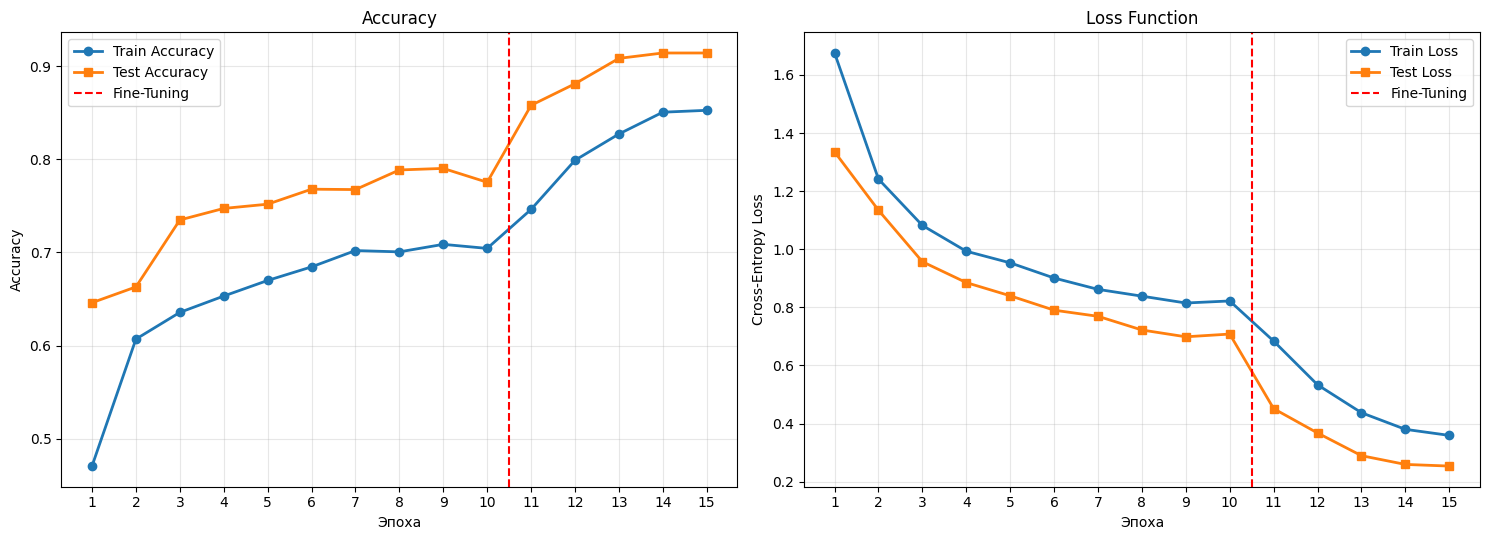

In [29]:
best_ckpt = torch.load("resnet50_mushrooms_best.pth", map_location=device, weights_only=True)
model.load_state_dict(best_ckpt["model_state_dict"])
model.eval()

full_train_acc = history_stage1["train_acc"] + history_stage2["train_acc"]
full_test_acc = history_stage1["test_acc"] + history_stage2["test_acc"]
full_train_loss = history_stage1["train_loss"] + history_stage2["train_loss"]
full_test_loss = history_stage1["test_loss"] + history_stage2["test_loss"]

epochs = range(1, len(full_train_acc) + 1)
split_epoch = len(history_stage1["train_acc"]) + 0.5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

ax1.plot(epochs, full_train_acc, label="Train Accuracy", marker="o", linewidth=2)
ax1.plot(epochs, full_test_acc, label="Test Accuracy", marker="s", linewidth=2)
ax1.axvline(x=split_epoch, color="red", linestyle="--", label="Fine-Tuning")
ax1.set_title(f"Accuracy")
ax1.set_xlabel("Эпоха")
ax1.set_ylabel("Accuracy")
ax1.set_xticks(epochs)
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(epochs, full_train_loss, label="Train Loss", marker="o", linewidth=2)
ax2.plot(epochs, full_test_loss, label="Test Loss", marker="s", linewidth=2)
ax2.axvline(x=split_epoch, color="red", linestyle="--", label="Fine-Tuning")
ax2.set_title("Loss Function")
ax2.set_xlabel("Эпоха")
ax2.set_ylabel("Cross-Entropy Loss")
ax2.set_xticks(epochs)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Classification report: Fine-Tuned ResNet50:

              precision    recall  f1-score   support

    Agaricus     0.8824    0.9756    0.9266       123
     Amanita     0.9466    0.9151    0.9306       271
     Boletus     0.9761    0.9659    0.9710       381
 Cortinarius     0.9024    0.8576    0.8795       302
    Entoloma     0.8467    0.9478    0.8944       134
   Hygrocybe     0.9817    0.9727    0.9772       110
   Lactarius     0.8988    0.9067    0.9027       568
     Russula     0.9126    0.8554    0.8831       415
     Suillus     0.8261    0.9744    0.8941       117

    accuracy                         0.9141      2421
   macro avg     0.9081    0.9301    0.9177      2421
weighted avg     0.9157    0.9141    0.9140      2421



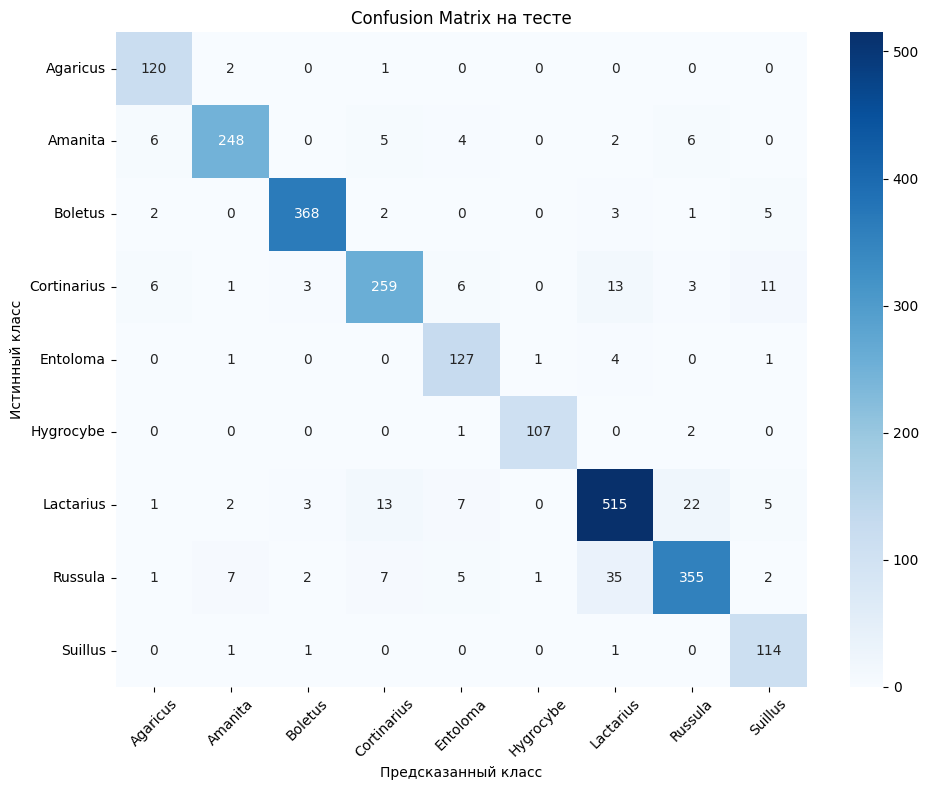

In [30]:
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

class_names = best_ckpt["class_names"]

print("Classification report: Fine-Tuned ResNet50:\n")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix на тесте")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()